In [1]:
import pandas as pd, numpy as np

In [2]:
df = pd.read_csv("../data/raw/status.csv")
df

,user_id,loan_count,avg_transaction_amount,days_since_last_activity,is_churn,churn_date
0,1,7,4.252810e+06,51,0,NaN
1,2,6,3.331625e+06,39,0,NaN
2,3,6,3.574123e+06,33,0,NaN
3,4,2,2.630618e+06,33,0,NaN
4,5,5,4.629785e+06,29,0,NaN
...,...,...,...,...,...,...
245,246,2,3.301796e+06,10,0,NaN
246,247,1,1.134780e+06,89,1,1.737763e+18
247,248,7,2.721008e+06,77,0,NaN
248,249,1,3.201004e+06,16,0,NaN


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 6 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   250 non-null    int64  
 1   loan_count                250 non-null    int64  
 2   avg_transaction_amount    250 non-null    float64
 3   days_since_last_activity  250 non-null    int64  
 4   is_churn                  250 non-null    int64  
 5   churn_date                74 non-null     float64
dtypes: float64(2), int64(4)
memory usage: 11.8 KB


<Axes: xlabel='avg_transaction_amount', ylabel='Count'>

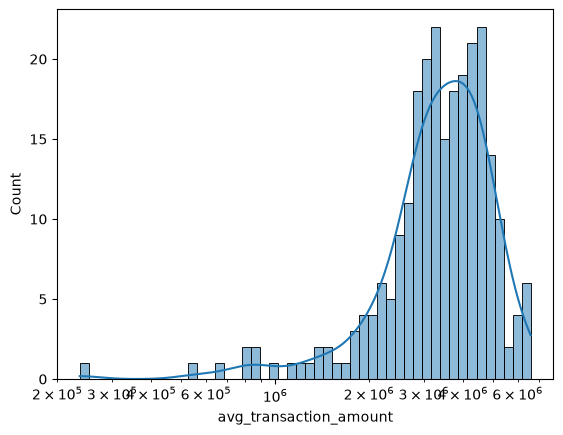

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x='avg_transaction_amount', bins=50, kde=True, log_scale=True)

In [9]:
print(f"Minimun amount of transaction: {min(df['avg_transaction_amount'])}")
print(f"Maximum amount of transaction: {max(df['avg_transaction_amount'])}")

Minimun amount of transaction: 235797.0
Maximum amount of transaction: 6593978.0


In [13]:
# Comparasion for transactions.csv
df.loc[df['user_id'].isin([60, 70, 116, 127, 135, 159, 179, 196, 235, 237]), ['user_id', 'avg_transaction_amount']]

,user_id,avg_transaction_amount
59,60,3.293933e+06
69,70,2.429921e+06
115,116,4.119352e+06
126,127,2.207785e+06
134,135,4.445928e+06
158,159,2.865694e+06
178,179,3.233035e+06
195,196,3.595654e+06
234,235,3.159132e+06
236,237,6.170928e+06


In [15]:
print(f"Number of null values: \n{df.isna().sum()}")
print(f"\nNumber of duplicate value: {df.duplicated().sum()}")

Number of null values: 
user_id                       0
loan_count                    0
avg_transaction_amount        0
days_since_last_activity      0
is_churn                      0
churn_date                  176
dtype: int64

Number of duplicate value: 0


In [16]:
status = df.copy()
status["churn_date"] = pd.to_datetime(status["churn_date"], unit="ns")
status = status.drop(columns=["days_since_last_activity"])
status

,user_id,loan_count,avg_transaction_amount,is_churn,churn_date
0,1,7,4.252810e+06,0,NaT
1,2,6,3.331625e+06,0,NaT
2,3,6,3.574123e+06,0,NaT
3,4,2,2.630618e+06,0,NaT
4,5,5,4.629785e+06,0,NaT
...,...,...,...,...,...
245,246,2,3.301796e+06,0,NaT
246,247,1,1.134780e+06,1,2025-01-25
247,248,7,2.721008e+06,0,NaT
248,249,1,3.201004e+06,0,NaT


In [17]:
status.to_csv("../data/clean/status_clean.csv")